# EDA — ad click prediction ("None" problem)

Sprint 2 exploratory analysis. Dataset: `data/synthetic_data_243.csv`, 1000 rows of
synthetic ad-impression data with a binary `clicked_ad` label.

The question this notebook is trying to answer: **what does the data actually look
like, and what does that force us to do differently because the target is a "None"
problem?** Concretely, whether the 98% background class can be ignored, whether any
feature separates clicks from non-clicks, and what that means for preprocessing and
for metrics later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

DATA_PATH = "data/synthetic_data_243.csv"
df = pd.read_csv(DATA_PATH)

## 1. Shape and column types

In [2]:
print(f"rows: {df.shape[0]}, columns: {df.shape[1]}")
print()
print(df.dtypes.to_string())

rows: 1000, columns: 8

user_age                          float64
gender                             object
device_type                        object
time_of_day                        object
ad_placement_position              object
ad_category                        object
previous_clicks_on_similar_ads    float64
clicked_ad                          int64


In [3]:
df.head(8)

,user_age,gender,device_type,time_of_day,ad_placement_position,ad_category,previous_clicks_on_similar_ads,clicked_ad
0,41.08,Male,Mobile,Afternoon,Footer,Technology,1.490,0
1,43.11,Male,Mobile,Evening,Footer,Gaming,0.344,0
2,44.96,Male,Desktop,Afternoon,Top-of-page,E-commerce,0.919,0
3,39.74,Male,Mobile,Afternoon,In-content,Travel,0.745,0
4,17.12,Male,Mobile,Afternoon,Top-of-page,Technology,2.230,0
5,39.08,Male,Mobile,Morning,In-content,E-commerce,1.930,0
6,35.52,Male,Mobile,Morning,In-content,Gaming,1.670,0
7,52.38,Male,Mobile,Evening,Top-of-page,Travel,0.983,0


Two numeric columns, five categorical, one integer target. `previous_clicks_on_similar_ads`
is named like a count but is stored as float — worth checking before treating it as one.

## 2. Data quality: missing values, duplicates, ranges

In [4]:
missing = df.isna().sum()
print("missing per column:")
print(missing.to_string())

feature_cols = [c for c in df.columns if c != "clicked_ad"]
print(f"\nfully duplicated rows: {df.duplicated().sum()}")
print(f"duplicated on features only: {df[feature_cols].duplicated().sum()}")
print(f"unique feature combinations: {df[feature_cols].drop_duplicates().shape[0]} of {len(df)}")

missing per column:
user_age                          0
gender                            0
device_type                       0
time_of_day                       0
ad_placement_position             0
ad_category                       0
previous_clicks_on_similar_ads    0
clicked_ad                        0

fully duplicated rows: 0
duplicated on features only: 0
unique feature combinations: 1000 of 1000


In [5]:
num_cols = ["user_age", "previous_clicks_on_similar_ads"]
df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(2)

,min,25%,50%,75%,max
user_age,6.99,28.38,35.11,41.98,69.32
previous_clicks_on_similar_ads,0.05,0.92,1.60,2.60,9.93


In [6]:
print("users under 18:", int((df.user_age < 18).sum()))
print("users under 13:", int((df.user_age < 13).sum()))
print("minimum age:", df.user_age.min())
print()
fractional = int((df.previous_clicks_on_similar_ads % 1 != 0).sum())
print(f"fractional values in previous_clicks_on_similar_ads: {fractional} of {len(df)}")
print("range:", df.previous_clicks_on_similar_ads.min(), "to", df.previous_clicks_on_similar_ads.max())

users under 18: 45
users under 13: 11
minimum age: 6.99

fractional values in previous_clicks_on_similar_ads: 994 of 1000
range: 0.0479 to 9.93


Good news: **no missing values, no duplicate rows, every row a unique feature
combination.** So imputation and de-duplication are not workstreams for this project,
which removes a whole class of leakage risk early.

Two things to fix or at least decide about:

1. **Ages below 18 (45 rows, minimum 6.99).** For an ad-click use case that's a
   legal/ethical problem rather than a modelling one, but it also means the age
   distribution has a tail that doesn't belong to the target population. Worth
   either filtering or at minimum documenting.
2. **`previous_clicks_on_similar_ads` is 99.4% fractional** — so it is not a count in
   this file, it's a continuous synthetic variable disguised as one. Treat it as
   continuous (which is what the modelling will do), and don't build count-specific
   features like "has never clicked" without deciding where the threshold goes.

## 3. The target: 2% positives

This is the "None" shape in its simplest form — one positive class, and a background
class that absorbs everything else.

In [7]:
counts = df.clicked_ad.value_counts().sort_index()
n, k = len(df), int(counts[1])
rate = k / n
print(counts.rename({0: "no click (none)", 1: "click"}).to_string())
print(f"\nclick rate: {rate:.2%}  ({k} positives, {n - k} negatives)")
print(f"imbalance ratio: 1 : {(n - k) / k:.0f}")
print(f"always-predict-none accuracy: {1 - rate:.2%}")

z = 1.96
den = 1 + z**2 / n
centre = (rate + z**2 / (2 * n)) / den
half = z * np.sqrt(rate * (1 - rate) / n + z**2 / (4 * n**2)) / den
print(f"95% Wilson CI for the positive rate: [{centre - half:.2%}, {centre + half:.2%}]")

clicked_ad
no click (none)    980
click               20

click rate: 2.00%  (20 positives, 980 negatives)
imbalance ratio: 1 : 49
always-predict-none accuracy: 98.00%
95% Wilson CI for the positive rate: [1.30%, 3.07%]


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
counts.plot.bar(ax=axes[0], color=["#8899aa", "#cc5544"])
axes[0].set_title("class counts")
axes[0].set_xlabel("clicked_ad")
axes[0].tick_params(axis="x", rotation=0)

axes[1].bar(["none", "click"], counts.values, color=["#8899aa", "#cc5544"])
axes[1].set_yscale("log")
axes[1].set_title("same counts, log scale")
plt.tight_layout()
plt.show()

<Figure size 990x330 with 2 Axes>

Two consequences that shape everything downstream:

- **Accuracy is dead as a metric.** Predicting "none" for every row scores 98%.
  Any model we report has to be scored on precision/recall, PR-AUC or a thresholded
  operating point, not accuracy.
- **20 positives is a very small number.** One misclassified click moves recall by
  5 percentage points, so a recall estimate has a 95% interval roughly ±20pp wide.
  Differences between models below ~10pp on recall are not meaningful on this data.
  That's a finding about the dataset, not a modelling failure, and it should be
  stated rather than hidden behind a single number.

## 4. Categorical features against the target

In [9]:
cat_cols = ["gender", "device_type", "time_of_day", "ad_placement_position", "ad_category"]

rows = []
for c in cat_cols:
    ct = pd.crosstab(df[c], df.clicked_ad)
    chi2, pval, dof, expected = stats.chi2_contingency(ct)
    rows.append({
        "feature": c,
        "levels": df[c].nunique(),
        "chi2": round(chi2, 2),
        "p_value": round(pval, 4),
        "min_expected_count": round(expected.min(), 2),
    })

pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)

,feature,levels,chi2,p_value,min_expected_count
0,ad_category,6,22.76,0.0004,1.0
1,gender,3,4.25,0.1193,0.8
2,time_of_day,4,2.36,0.5018,2.0
3,device_type,3,1.11,0.5747,1.0
4,ad_placement_position,4,1.73,0.6301,1.0


In [10]:
for c in cat_cols:
    tab = (df.groupby(c)["clicked_ad"]
             .agg(n="count", clicks="sum", rate="mean")
             .sort_values("rate", ascending=False))
    tab["rate"] = (tab["rate"] * 100).round(1)
    print(f"\n{c}")
    print(tab.to_string())


gender
          n  clicks  rate
gender                   
Male    480      14   2.9
Female  480       6   1.2
Other    40       0   0.0

device_type
               n  clicks  rate
device_type                   
Desktop      250       7   2.8
Tablet        50       1   2.0
Mobile       700      12   1.7

time_of_day
               n  clicks  rate
time_of_day                   
Night        100       4   4.0
Morning      250       5   2.0
Afternoon    350       6   1.7
Evening      300       5   1.7

ad_placement_position
                         n  clicks  rate
ad_placement_position                   
In-content             350       9   2.6
Sidebar                200       4   2.0
Top-of-page            400       7   1.8
Footer                  50       0   0.0

ad_category
               n  clicks  rate
ad_category                   
Gaming       100       7   7.0
Education     50       2   4.0
Travel       150       6   4.0
Technology   250       2   0.8
E-commerce   300       2   

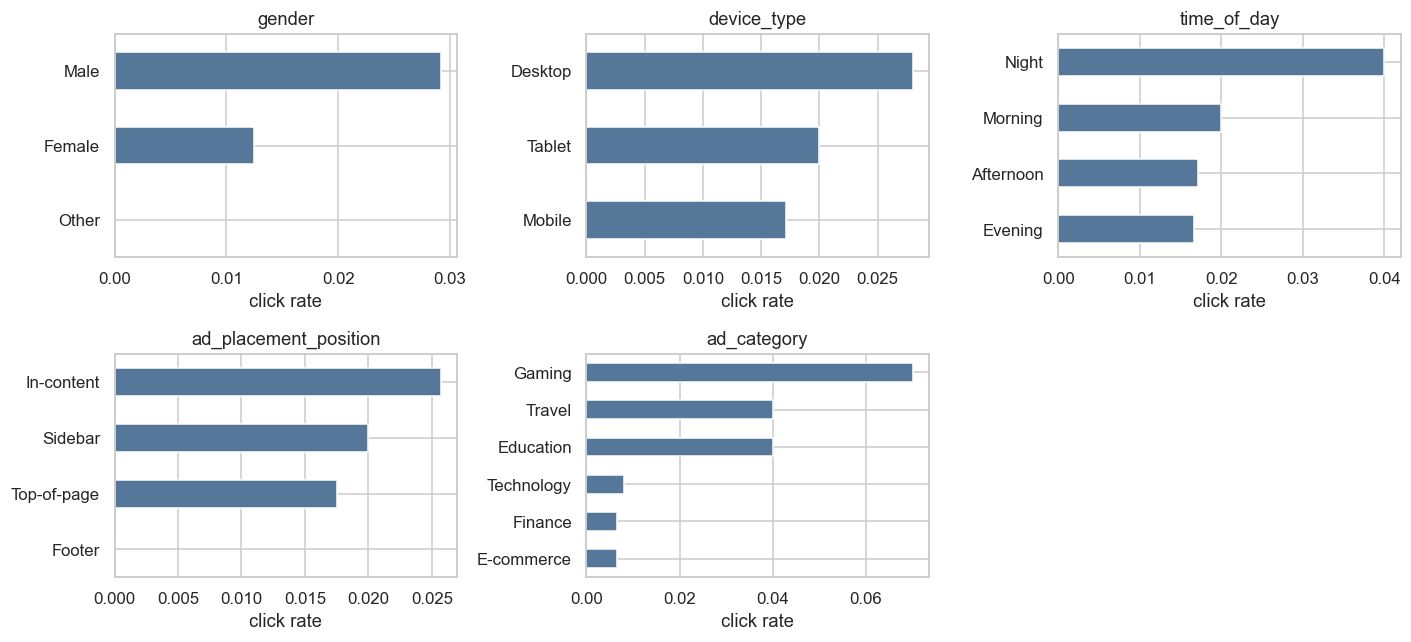

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), cat_cols):
    rates = df.groupby(c)["clicked_ad"].mean().sort_values()
    rates.plot.barh(ax=ax, color="#557799")
    ax.set_title(c)
    ax.set_xlabel("click rate")
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

Only **`ad_category`** clears a conventional significance bar (chi² = 22.76, p = 0.0004).
Gaming sits at 7% and Travel/Education at 4%, against under 1% for Technology and
E-commerce. Gender is borderline at p = 0.12 but with 6 clicks among 480 women and 0
among 40 in the "Other" level, that's noise as much as signal. Device, time of day
and placement position show nothing at all (p > 0.5).

Caveat on the chi-square: with 20 positives several expected cell counts are around 1,
so the test is only indicative. The direction of the effect is more trustworthy than
the p-value.

## 5. Continuous features against the target

In [12]:
for col in num_cols:
    pos = df.loc[df.clicked_ad == 1, col]
    neg = df.loc[df.clicked_ad == 0, col]
    t_stat, p_t = stats.ttest_ind(pos, neg, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(pos, neg)
    print(f"{col}")
    print(f"  positive class: mean {pos.mean():.2f}, median {pos.median():.2f} (n={len(pos)})")
    print(f"  negative class: mean {neg.mean():.2f}, median {neg.median():.2f} (n={len(neg)})")
    print(f"  Welch t-test p = {p_t:.4g} | Mann-Whitney p = {p_u:.4g}\n")

user_age
  positive class: mean 36.44, median 34.03 (n=20)
  negative class: mean 35.05, median 35.13 (n=980)
  Welch t-test p = 0.6255 | Mann-Whitney p = 0.6802

previous_clicks_on_similar_ads
  positive class: mean 0.45, median 0.32 (n=20)
  negative class: mean 1.96, median 1.62 (n=980)
  Welch t-test p = 2.68e-16 | Mann-Whitney p = 2.265e-10



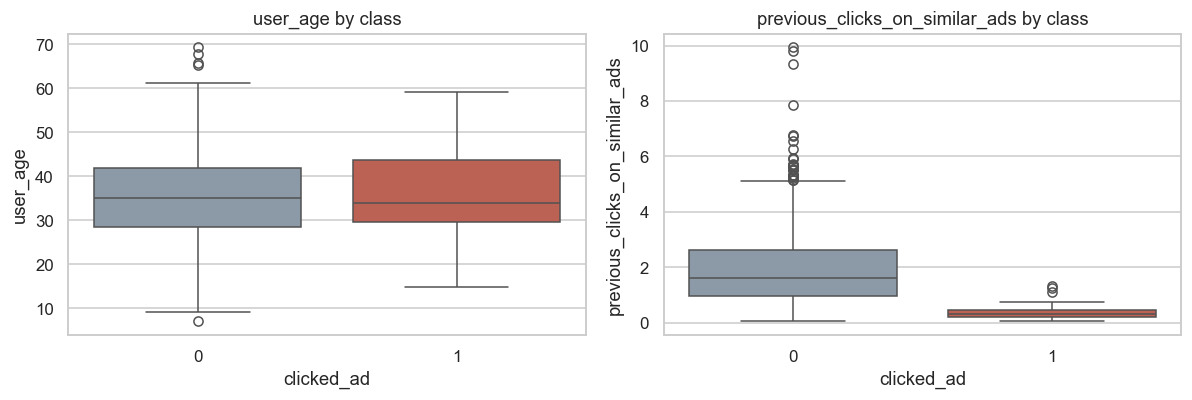

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="clicked_ad", y=col, hue="clicked_ad",
                palette=["#8899aa", "#cc5544"], legend=False, ax=ax)
    ax.set_title(f"{col} by class")
    ax.set_xlabel("clicked_ad")
plt.tight_layout()
plt.show()

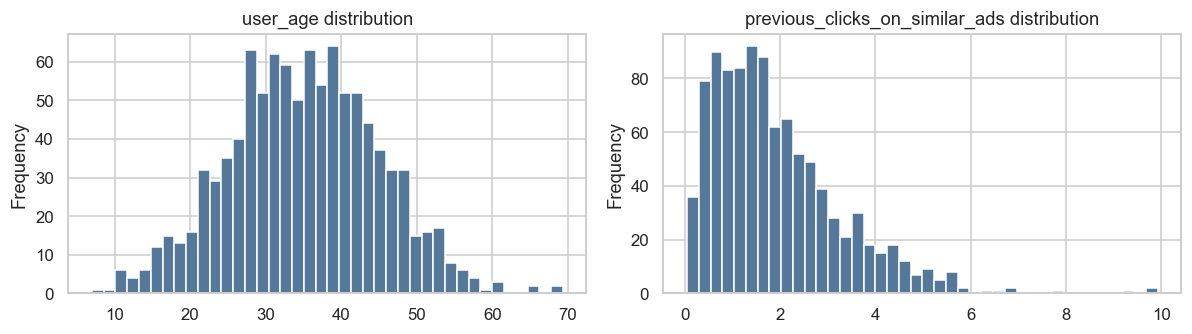

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col in zip(axes, num_cols):
    df[col].plot.hist(bins=40, ax=ax, color="#557799")
    ax.set_title(f"{col} distribution")
plt.tight_layout()
plt.show()

`user_age` carries no signal at all (p = 0.63). `previous_clicks_on_similar_ads` is the
opposite story: clickers average 0.45 prior clicks against 1.96 for non-clickers, and
both tests are about as significant as they get. The direction is counter-intuitive —
**more prior clicks on similar ads is associated with not clicking this one** — which
in a synthetic dataset probably just means the generator drew them from different
distributions per class. Worth flagging rather than interpreting as user behaviour.

In [15]:
age_bins = pd.cut(df.user_age, bins=[0, 18, 25, 35, 45, 55, 70])
df.assign(age_bin=age_bins).groupby("age_bin", observed=True)["clicked_ad"].agg(
    n="count", clicks="sum", rate="mean").round(3)

,n,clicks,rate
age_bin,,,
"(0, 18]",45,1,0.022
"(18, 25]",114,3,0.026
"(25, 35]",337,7,0.021
"(35, 45]",345,4,0.012
"(45, 55]",140,3,0.021
"(55, 70]",19,2,0.105


In [16]:
click_bins = pd.cut(df.previous_clicks_on_similar_ads, bins=[-0.01, 0.5, 1, 2, 3, 10])
df.assign(click_bin=click_bins).groupby("click_bin", observed=True)["clicked_ad"].agg(
    n="count", clicks="sum", rate="mean").round(3)

,n,clicks,rate
click_bin,,,
"(-0.01, 0.5]",101,16,0.158
"(0.5, 1.0]",180,1,0.006
"(1.0, 2.0]",328,3,0.009
"(2.0, 3.0]",210,0,0.000
"(3.0, 10.0]",181,0,0.000


Binned, the shape is clear: click rate is 15.8% when prior clicks are at or below 0.5,
and **zero clicks out of 391 rows** above 2. So almost all the signal in this dataset
lives in one variable and one region of it. Everything else is close to noise.

## 6. Correlations and mutual information

In [17]:
corr = df[num_cols + ["clicked_ad"]].corr(method="spearman")
corr.round(3)

,user_age,previous_clicks_on_similar_ads,clicked_ad
user_age,1.000,0.090,0.013
previous_clicks_on_similar_ads,0.090,1.000,-0.201
clicked_ad,0.013,-0.201,1.000


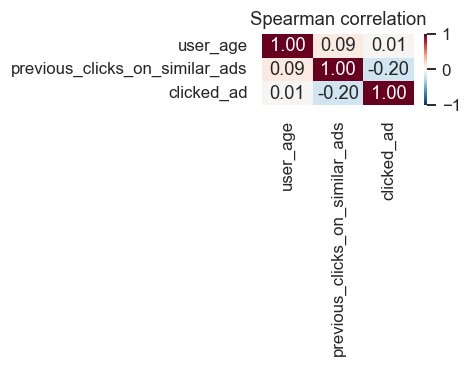

In [18]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
plt.tight_layout()
plt.show()

In [19]:
X = pd.get_dummies(df.drop(columns=["clicked_ad"]), drop_first=True)
mi = pd.Series(
    mutual_info_classif(X, df.clicked_ad, random_state=RANDOM_STATE),
    index=X.columns,
).sort_values(ascending=False)
mi.round(4).to_frame("mutual_information")

,mutual_information
previous_clicks_on_similar_ads,0.0409
time_of_day_Evening,0.0083
device_type_Mobile,0.0062
gender_Male,0.0054
ad_category_Travel,0.0028
ad_placement_position_In-content,0.0026
ad_category_Finance,0.0016
ad_category_Technology,0.0009
ad_placement_position_Top-of-page,0.0004
ad_category_Gaming,0.0000


No multicollinearity to worry about — the two numeric features correlate at 0.09.

Mutual information agrees on the top feature and then gets noisy:
`previous_clicks_on_similar_ads` is 0.041, and everything else is 0.01 or below. Note
that the ranking past the first row contradicts the chi-square results — `Gaming` scores
0.000 despite a 7% click rate, and `time_of_day_Evening` ranks second despite a
non-significant test. That disagreement is not a bug. With 20 positives, these scores
are unstable enough that the ordering of the tail shouldn't be read as signal, and a
different seed moves it. Treat MI here as confirmation that one feature dominates, not
as a feature-selection ranking we can trust.

If a feature-engineering sprint is going to find anything, it has to come from
interactions around the prior-clicks variable and `ad_category`, not from the
demographic columns.

## 7. How far does a single rule get us?

A useful sanity check before any model: if one threshold on one feature already
achieves most of what a classifier would, that's the baseline to beat, and it tells us
how much of the problem is genuinely multivariate.

In [20]:
pc = df.previous_clicks_on_similar_ads
rows = []
for threshold in [0.25, 0.5, 0.75, 1.0, 1.31, 1.5, 2.0, 3.0]:
    pred = (pc <= threshold).astype(int)
    tp = int(((pred == 1) & (df.clicked_ad == 1)).sum())
    fp = int(((pred == 1) & (df.clicked_ad == 0)).sum())
    fn = int(((pred == 0) & (df.clicked_ad == 1)).sum())
    tn = int(((pred == 0) & (df.clicked_ad == 0)).sum())
    rows.append({
        "rule": f"prev_clicks <= {threshold}",
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": round(tp / max(tp + fp, 1), 3),
        "recall": round(tp / max(tp + fn, 1), 3),
    })

pd.DataFrame(rows)

,rule,TP,FP,FN,TN,precision,recall
0,prev_clicks <= 0.25,6,19,14,961,0.240,0.30
1,prev_clicks <= 0.5,16,85,4,895,0.158,0.80
2,prev_clicks <= 0.75,16,172,4,808,0.085,0.80
3,prev_clicks <= 1.0,17,264,3,716,0.060,0.85
4,prev_clicks <= 1.31,20,370,0,610,0.051,1.00
5,prev_clicks <= 1.5,20,436,0,544,0.044,1.00
6,prev_clicks <= 2.0,20,589,0,391,0.033,1.00
7,prev_clicks <= 3.0,20,799,0,181,0.024,1.00


At `<= 0.5` the rule catches 16 of 20 clicks (recall 0.80) at a precision of 0.16 — that
is 85 false positives out of 1000 rows, i.e. an 8.5% flag rate for a 2% base rate.
At `<= 1.31` it catches all 20 clicks but flags 390 rows, precision 0.05.

So a single threshold is a real baseline: any model that can't beat 0.80 recall at 8.5%
flag rate has added nothing. Beating it means using `ad_category` and possibly the
interaction between category and prior clicks, which is consistent with the
chi-square result.

## 8. Where the "None" problem actually shows up in this data

Worth being precise, because "None classification" can mean two different things and
they lead to different evaluation setups.

**As constructed**, this is a 2% positive problem with a single background class. The
"none" outcome is "this user clicks none of the ads". A model that always answers
"none" is 98% accurate and useless, so the entire project is about the minority class
and about keeping the false-positive rate usable. That is the framing the rest of the
work should use.

**As an open-set problem**, the natural split is to treat `ad_category` as the class
space: train on five categories, hold one out entirely, and check whether clicks on the
held-out category get flagged as none or confidently misclassified as a known one. That
is the honest way to test open-set behaviour in tabular data. The problem is sample
size — holding out Travel removes 150 rows but only 6 positives, and holding out Gaming
removes 7 of the 20 positives. It is feasible as a sanity check, not as a headline
result. If this framing matters for the final report, more data is needed first.

## 9. Implications for preprocessing and modelling

| Decision | What the data says |
|---|---|
| Missing values | None. Don't build an imputation pipeline; a `SimpleImputer` in the pipeline is harmless but should not be presented as a finding. |
| Duplicates | None, and 1000/1000 unique feature rows. No dedup step needed. |
| Age validity | 45 rows under 18, min 6.99. Filter or document — decide before splitting so it isn't a silent test-set change. |
| `previous_clicks_on_similar_ads` | Continuous, not a count. Scale it for linear models; trees don't need it. |
| Categorical encoding | One-hot is fine — max cardinality is 6 (`ad_category`). No target encoding, so no encoding-leakage risk. |
| Scaling | Needed for logistic regression and k-NN, irrelevant for trees. Fit inside the pipeline regardless. |
| Feature selection | Two features carry nearly all the signal. Report the single-rule baseline so any added complexity has to justify itself. |
| Class balance | 1:49. Class weights first, threshold tuning second; resampling only as a comparison, never before the split. |
| Metrics | PR-AUC and recall at a fixed flag rate (e.g. 8.5% or 10%). Accuracy and AUROC as secondary. Report the fold spread or a CI, not a bare number. |
| Validation | Stratified k-fold with enough folds that each has positives — 5-fold gives ~4 positives per fold, 10-fold gives ~2. Prefer repeated stratified 5-fold and report the spread. |
| Leakage watch | Nothing in the columns is a proxy for the label, and no column is computed after the click. The one real risk is resampling or feature selection outside the split. |

## 10. Takeaways

1. Clean file: no missing values, no duplicates, no obvious leakage columns.
2. Severe imbalance (2%, 1:49) with only 20 positives, which caps how precise any
   model comparison can be and makes accuracy meaningless.
3. `previous_clicks_on_similar_ads` is the dominant feature and its effect is
   monotone and negative: rate 15.8% below 0.5, 0% above 2.
4. `ad_category` is the only other feature with a plausible effect (Gaming 7%);
   demographics and placement are noise at this sample size.
5. A one-threshold rule reaches 0.80 recall at 0.16 precision — that's the baseline.
6. Two data-quality issues to settle before modelling: under-18 rows, and the
   mislabelled count variable.
7. Open-set evaluation via a held-out `ad_category` is possible but underpowered with
   20 positives, so it stays a sanity check unless the dataset grows.